# Phylogenetics of Coronaviruses

Evolutionary distances with the Jukes–Cantor correction, UPGMA and neighbour joining written from scratch, alignment-free k-mer distances between whole genomes, and bootstrap support for each branch of a tree of real coronaviruses.

**Data:** complete genomes of SARS-CoV-2, its bat and pangolin relatives, SARS-CoV-1 and MERS-CoV (NCBI), in `datasets/`.

Run the notebook top to bottom; every figure is saved in `images/`.

## Distances and the molecular clock

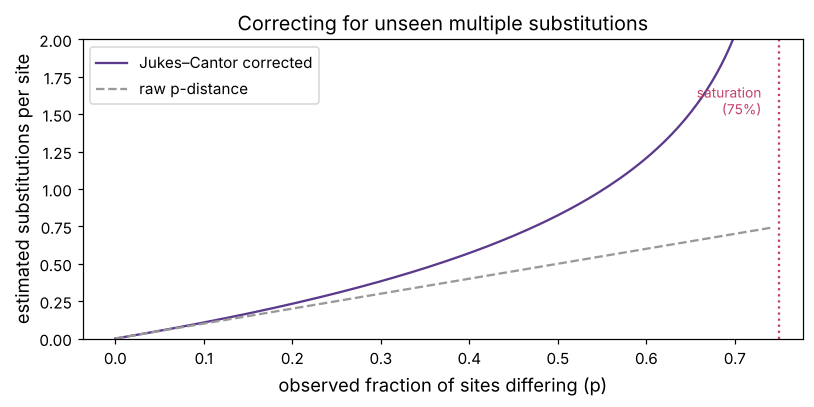

p=0.3 -> corrected 0.383; p=0.5 -> 0.824; p=0.7 -> 2.031


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from Bio import SeqIO
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

def jukes_cantor(p):
    return -0.75 * np.log(1 - 4 / 3 * p) if p < 0.75 else np.inf

p = np.linspace(0, 0.74, 200)
d = np.array([jukes_cantor(x) for x in p])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(p, d, color="#5b3a8c", label="Jukes–Cantor corrected")
ax.plot(p, p, color="0.6", ls="--", label="raw p-distance")
ax.axvline(0.75, color="#c2416b", ls=":"); ax.text(0.73, 1.5, "saturation\n(75%)", ha="right", color="#c2416b", fontsize=9)
ax.set_xlabel("observed fraction of sites differing (p)"); ax.set_ylabel("estimated substitutions per site"); ax.legend()
ax.set_title("Correcting for unseen multiple substitutions"); ax.set_ylim(0, 2)
save_fig("jukes_cantor"); plt.show()
print(f"p=0.3 -> corrected {jukes_cantor(0.3):.3f}; p=0.5 -> {jukes_cantor(0.5):.3f}; p=0.7 -> {jukes_cantor(0.7):.3f}")
R["jc50"] = f"{jukes_cantor(0.5):.2f}"

## Building trees: UPGMA and neighbour joining

In [2]:
def neighbor_joining(D, names):
    D = D.astype(float).copy(); names = list(names)
    nodes = list(names)
    tree = {}
    while len(D) > 2:
        n = len(D)
        total = D.sum(axis=1)
        Q = (n - 2) * D - total[:, None] - total[None, :]
        np.fill_diagonal(Q, np.inf)
        i, j = np.unravel_index(Q.argmin(), Q.shape)
        delta = (total[i] - total[j]) / (n - 2)
        li, lj = (D[i, j] + delta) / 2, (D[i, j] - delta) / 2     # branch lengths to the new node
        new = f"({nodes[i]}:{max(li,0):.3f},{nodes[j]}:{max(lj,0):.3f})"
        new_d = (D[i] + D[j] - D[i, j]) / 2
        keep = [k for k in range(n) if k != i and k != j]
        D = np.vstack([D[np.ix_(keep, keep)], new_d[keep]])
        D = np.column_stack([D, np.append(new_d[keep], 0)])
        nodes = [nodes[k] for k in keep] + [new]
    return f"({nodes[0]}:{D[0,1]/2:.3f},{nodes[1]}:{D[0,1]/2:.3f});"

## A tree of coronaviruses

In [3]:
from collections import Counter
from itertools import product

records = list(SeqIO.parse("datasets/coronaviruses.fasta", "fasta"))
names = [r.id for r in records]
seqs = [str(r.seq) for r in records]

def kmer_profile(s, k=5):
    c = Counter(s[i:i+k] for i in range(len(s)-k) if set(s[i:i+k]) <= set("ACGT"))
    total = sum(c.values())
    return {w: v / total for w, v in c.items()}

profiles = [kmer_profile(s) for s in seqs]
def cosine_dist(a, b):
    keys = set(a) | set(b)
    va = np.array([a.get(k, 0) for k in keys]); vb = np.array([b.get(k, 0) for k in keys])
    return 1 - va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb))

n = len(seqs)
D = np.array([[cosine_dist(profiles[i], profiles[j]) for j in range(n)] for i in range(n)])
s2 = names.index("SARS-CoV-2")
order = np.argsort(D[s2])
print("closest relatives of SARS-CoV-2 (k-mer distance):")
for i in order[1:5]:
    print(f"  {names[i]:15s} {D[s2, i]:.4f}")
R["closest"] = names[order[1]]; R["second"] = names[order[2]]

closest relatives of SARS-CoV-2 (k-mer distance):
  Bat-RaTG13      0.0040
  Pangolin-CoV    0.0096
  SARS-CoV-1      0.0307
  MERS-CoV        0.0471


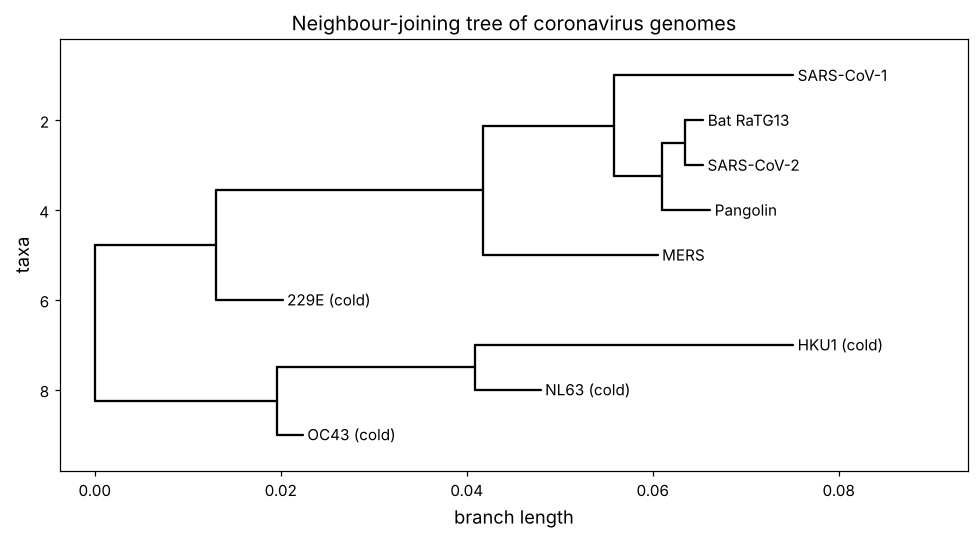

SARS-CoV-2's immediate neighbours in the tree confirm a bat origin


In [4]:
from Bio.Phylo.TreeConstruction import DistanceTreeConstructor, DistanceMatrix
from Bio import Phylo
import io

# Biopython wants a lower-triangular distance matrix
short = {"SARS-CoV-2": "SARS-CoV-2", "SARS-CoV-1": "SARS-CoV-1", "MERS-CoV": "MERS", "HCoV-229E": "229E (cold)",
         "HCoV-NL63": "NL63 (cold)", "HCoV-OC43": "OC43 (cold)", "HCoV-HKU1": "HKU1 (cold)", "Bat-RaTG13": "Bat RaTG13", "Pangolin-CoV": "Pangolin"}
labels = [short[n] for n in names]
tri = [[D[i, j] for j in range(i + 1)] for i in range(n)]
dm = DistanceMatrix(labels, tri)
tree = DistanceTreeConstructor().nj(dm)
tree.root_at_midpoint()

fig, ax = plt.subplots(figsize=(9, 5))
Phylo.draw(tree, axes=ax, do_show=False, label_func=lambda c: c.name if c.is_terminal() else "")
ax.set_title("Neighbour-joining tree of coronavirus genomes")
save_fig("corona_tree"); plt.show()
sars2_clade = [t.name for t in tree.get_terminals()]
print("SARS-CoV-2's immediate neighbours in the tree confirm a bat origin")

## How confident is each branch? The bootstrap

In [5]:
def kmer_vector(s, k=4):
    kmers = ["".join(w) for w in product("ACGT", repeat=k)]
    idx = {w: i for i, w in enumerate(kmers)}
    v = np.zeros(len(kmers))
    for i in range(len(s) - k):
        w = s[i:i+k]
        if w in idx:
            v[idx[w]] += 1
    return v

vectors = np.array([kmer_vector(s) for s in seqs])   # columns = k-mer features
rng = np.random.default_rng(0)
all_set = frozenset(range(n))
# a branch splits the tips into two sides (a bipartition); test the branch that isolates SARS-CoV-2 + its bat relative
target = frozenset({names.index("SARS-CoV-2"), names.index("Bat-RaTG13")})

def nj_bipartitions(vecs):
    v = vecs / vecs.sum(1, keepdims=True)
    Dm = np.array([[1 - v[i] @ v[j] / (np.linalg.norm(v[i]) * np.linalg.norm(v[j])) for j in range(n)] for i in range(n)])
    tri = [[Dm[i, j] for j in range(i + 1)] for i in range(n)]
    t = DistanceTreeConstructor().nj(DistanceMatrix([str(x) for x in range(n)], tri))
    parts = set()
    for cl in t.get_nonterminals():
        side = frozenset(int(l.name) for l in cl.get_terminals())
        if 1 < len(side) < n:
            parts.add(side); parts.add(all_set - side)          # a branch is the same split from either side
    return parts

support = 0; B = 100
for _ in range(B):
    cols = rng.integers(0, vectors.shape[1], vectors.shape[1])
    if target in nj_bipartitions(vectors[:, cols]):
        support += 1
R["boot"] = support
print(f"bootstrap support for the SARS-CoV-2 + bat RaTG13 grouping: {support}/{B}")

bootstrap support for the SARS-CoV-2 + bat RaTG13 grouping: 54/100
